![Python Banner](../../Image/05_02_meta_learners.png)


# 2.4. Causal ML with Targeted Maximum Likelihood Estimation (TMLE)


## Overview

The meta-learners covered in the preceding sections — S-, T-, X-, R-, and DR-Learners — share a common structure: they decompose the CATE estimation problem into supervised learning sub-problems and rely on base learners to approximate nuisance functions such as outcome regressions and propensity scores. A recurring limitation of this approach is that machine learning algorithms optimized for predictive accuracy introduce **regularization bias** — systematic shrinkage of estimates toward zero or toward the population mean — that invalidates standard confidence intervals and hypothesis tests. **Targeted Maximum Likelihood Estimation (TMLE)** addresses this limitation directly. Rather than replacing the meta-learner framework, TMLE acts as a **bias-correction and inference layer** that can be applied on top of any initial ML-based estimate to produce statistically valid, efficient causal effect estimates.

TMLE was developed primarily by Mark van der Laan and colleagues and belongs to the broader family of **targeted learning** methods, which combine the flexibility of nonparametric machine learning with the rigor of semiparametric efficiency theory.

---

### The Core Problem TMLE Solves

To understand TMLE's role, it helps to contrast the two approaches it synthesizes.

**Traditional parametric statistics** — linear regression, logistic regression — make strong structural assumptions about the data-generating process. When those assumptions hold, the resulting estimators are unbiased and admit closed-form inference. When they fail, the estimates are biased in ways that are difficult to detect or correct.

**Machine learning** imposes far weaker assumptions and can approximate complex, high-dimensional relationships between covariates, treatments, and outcomes. However, ML algorithms optimize a global prediction loss (e.g., mean squared error) rather than the specific causal parameter of interest. The regularization they apply — $\ell_1$ or $\ell_2$ penalties, early stopping, tree depth limits — reduces prediction variance at the cost of introducing bias into the causal estimate. This **regularization bias** is first-order: it does not vanish asymptotically at the rate needed for valid confidence interval construction.

TMLE resolves this tension. It uses ML algorithms to flexibly estimate the nuisance functions that characterize the data distribution, then applies a targeted **fluctuation step** that removes the first-order bias relevant to the causal parameter. The result is an estimator that combines the approximation power of ML with asymptotically valid inference.

---

### How TMLE Works

TMLE is a **two-stage substitution estimator**. We describe it here for the canonical estimand, the Average Treatment Effect (ATE), before discussing its extension to the CATE.

#### Notation

| Symbol | Meaning |
|--------|---------|
| $X$ | Covariates (pre-treatment features) |
| $A \in \{0,1\}$ | Binary treatment indicator |
| $Y$ | Observed outcome |
| $Q(A, X) = \mathbb{E}[Y \mid A, X]$ | Outcome regression |
| $g(X) = P(A = 1 \mid X)$ | Propensity score |

#### Stage 1: Initial Estimation

Using any flexible ML algorithm — random forests, gradient boosting, a SuperLearner ensemble — estimate two nuisance functions on the observed data:

1. **Outcome regression**: $\hat{Q}(A, X) = \hat{\mathbb{E}}[Y \mid A, X]$
2. **Propensity score**: $\hat{g}(X) = \hat{P}(A = 1 \mid X)$

At this stage, both estimates are optimized for prediction accuracy. They are good approximations to the true nuisance functions but contain regularization bias that makes them unsuitable for direct causal inference.

#### Stage 2: The Targeting Step

This is the defining innovation of TMLE. The initial outcome estimate $\hat{Q}$ is updated to a **targeted estimate** $\hat{Q}^*$ by fitting a one-dimensional fluctuation model. Specifically, a logistic regression is fit with:

- **Outcome**: $Y$
- **Offset**: $\text{logit}(\hat{Q}(A, X))$ (the initial estimate, held fixed)
- **Single predictor**: the **clever covariate** $H(A, X)$, defined as:

$$H(A, X) = \frac{A}{\hat{g}(X)} - \frac{1 - A}{1 - \hat{g}(X)}$$

The clever covariate is the **efficient influence function (EIF)** of the ATE with respect to the outcome model. By including it as the sole predictor in the fluctuation regression, TMLE solves the score equation for the EIF, which is precisely the condition required for:

1. **Debiasing**: the first-order bias from nuisance misspecification is removed.
2. **Local efficiency**: the estimator achieves the semiparametric efficiency bound asymptotically.

The fitted coefficient $\hat{\epsilon}$ from the fluctuation regression is used to update the outcome model:

$$\hat{Q}^*(A, X) = \text{expit}\!\left(\text{logit}(\hat{Q}(A, X)) + \hat{\epsilon} \cdot H(A, X)\right)$$

#### Stage 3: Substitution

The targeted outcome estimate $\hat{Q}^*$ is plugged into the ATE formula:

$$\widehat{\text{ATE}}_{\text{TMLE}} = \frac{1}{n} \sum_{i=1}^{n} \left[ \hat{Q}^*(1, X_i) - \hat{Q}^*(0, X_i) \right]$$

Because $\hat{Q}^*$ has been targeted, this plug-in estimate is doubly robust and semiparametrically efficient. A valid influence-function-based standard error is:

$$\widehat{\text{SE}} = \frac{1}{\sqrt{n}} \cdot \text{sd}\!\left( \hat{Q}^*(1, X_i) - \hat{Q}^*(0, X_i) + H(A_i, X_i)(Y_i - \hat{Q}^*(A_i, X_i)) \right)$$

which enables asymptotically valid confidence intervals and hypothesis tests without bootstrap resampling.

---

### Key Properties

**Double robustness.** The TMLE estimator of the ATE is consistent if *either* the outcome model $Q$ *or* the propensity score $g$ is consistently estimated — but not necessarily both. This provides a meaningful safety net against misspecification of one of the two nuisance components. Importantly, when both nuisance models converge at sufficiently fast rates (each at $n^{-1/4}$ or faster), the TMLE achieves $\sqrt{n}$-consistency and asymptotic normality even when both are estimated nonparametrically.

**Semiparametric efficiency.** Under regularity conditions, TMLE achieves the Cramér-Rao lower bound for the semiparametric model — the minimum asymptotic variance among all regular estimators. This implies that no estimator can produce narrower valid confidence intervals from the same data, asymptotically.

**Valid inference without bootstrapping.** The influence-function-based standard error is computed analytically from a single model fit, making TMLE inference computationally cheap compared to bootstrap-based approaches. This is particularly valuable in large datasets where bootstrapping is prohibitively expensive.

**Respects parameter bounds.** Because TMLE is a substitution estimator — it plugs a model prediction into a closed-form formula — the resulting estimate inherits the natural bounds of the outcome. If $Y \in [0, 1]$, the TMLE ATE estimate lies in $[-1, 1]$ and CATE estimates lie in $[0, 1]$. Moment-condition estimators such as DML do not share this property and can produce estimates outside valid ranges in finite samples.

---

### TMLE vs. Double Machine Learning (DML)

DML (Chernozhukov et al., 2018) is the most closely related estimator to TMLE. Both exploit **Neyman orthogonality** — the property that the estimating equation is insensitive to first-order errors in the nuisance estimates — and both employ **cross-fitting** to avoid overfitting bias from using the same data to estimate nuisance functions and the target parameter. Their differences are primarily in construction and finite-sample behavior:

| Property | TMLE | DML |
|----------|------|-----|
| **Construction** | Likelihood fluctuation (substitution) | Moment condition (score equation) |
| **Parameter bounds** | Guaranteed | Not guaranteed |
| **Finite-sample efficiency** | Generally higher | Slightly lower |
| **Implementation complexity** | Moderate | Lower |
| **High-dimensional parameters** | Extensions available | More natural |

In practice, TMLE is preferred when outcome bounds must be respected or when finite-sample efficiency is at a premium — common in medical and policy applications with moderate sample sizes. DML is often preferred for its simplicity and scalability in high-dimensional settings.

---

### TMLE for CATE Estimation

Standard TMLE as described above targets the **ATE** — a single population-average quantity. Extending it to the **CATE**, $\tau(x) = \mathbb{E}[Y(1) - Y(0) \mid X = x]$, requires targeting a function rather than a scalar, which demands more care.

**Stratified TMLE** is the simplest approach: partition the covariate space into subgroups and apply standard TMLE within each stratum. This provides valid inference for subgroup-average effects but does not produce a smooth CATE function and suffers from the usual curse of dimensionality for fine partitions.

**Targeted CATE learning** uses a modified fluctuation step in which the clever covariate is made covariate-dependent:

$$H(A, X) = \frac{A \cdot b(X)}{\hat{g}(X)} - \frac{(1-A) \cdot b(X)}{1 - \hat{g}(X)}$$

where $b(X)$ is a basis function or a flexible function of $X$ chosen to target the conditional effect. The fluctuation is then fit with multiple clever covariates, one per basis element, producing a targeted update of $\hat{Q}$ that is biased toward the CATE rather than the ATE.

**TMLE inside meta-learners.** A practically important use case is applying TMLE as the final estimation step within a meta-learner structure. For example, the DR-Learner's pseudo-outcomes can be constructed using a TMLE-corrected $\hat{Q}^*$ rather than the raw ML outcome estimate, combining the structural flexibility of the meta-learner with the debiasing guarantees of TMLE.

The primary advantage of TMLE for CATE estimation in applied uplift modeling is **uncertainty quantification**: while methods such as causal forests provide point estimates of $\tau(x)$, they rely on bootstrap or subsampling variance estimators that can be unstable in small samples. TMLE-based CATE estimators provide influence-function standard errors that are valid under weaker conditions and are more computationally efficient to construct.

---

### Relationship to the Meta-Learner Framework

It is important to distinguish TMLE's role from that of the meta-learners described in the preceding sections. Meta-learners — S, T, X, R, DR — define the **structural decomposition** of the CATE estimation problem: how models are organized, what they are trained to predict, and how their outputs are combined. TMLE defines an **estimation and inference procedure**: how bias is removed from an initial estimate and how valid uncertainty measures are constructed.

These two dimensions are largely orthogonal and can be combined freely. Any meta-learner that produces an initial CATE estimate can, in principle, be followed by a TMLE targeting step to debias the estimate and enable valid inference. In this sense, TMLE is best understood not as a competitor to the meta-learner framework but as a complementary tool that addresses the inferential limitations that meta-learners, as pure estimation strategies, leave unresolved.

---

### Summary

| Feature | Standard ML Uplift | DML | TMLE |
|---------|-------------------|-----|------|
| **Bias correction** | None / heuristic | Neyman orthogonality | EIF fluctuation |
| **Inference** | Bootstrap (unstable) | Asymptotically normal | Asymptotically normal |
| **Parameter bounds** | Not guaranteed | Not guaranteed | Guaranteed |
| **Efficiency** | Lower | High | Semiparametrically optimal |
| **CATE uncertainty** | Limited | Moderate | Strong |
| **Best used when** | Exploratory analysis | High-dimensional controls | Precision inference required |


## Implementation in Python

This notebook implements the same workflow as the [Python example](https://causalml.readthedocs.io/en/latest/examples/validation_with_tmle.html) to demonstrate how TMLE can be used for validating uplift models. We use **PyCausalML** for meta-learners and gain/Qini curves, a Python TMLE fluctuation for the targeting step, and the NSW job-training sample from `causaldata` for the LaLonde use case.

- **Part A: Synthetic data** — known τ: same DGP as the Python example (`mode=1`, `p=10`, `sigma=5`). We compare uplift with and without τ, then TMLE-based curves.

- **Part B: Use case (LaLonde)** — real observational data with **no** individual τ: the same validation idea (observed-only uplift vs segment-level TMLE as a proxy).

Within Part A:

1. **Generating synthetic data** — same DGP as the Python example (`mode=1`, `p=10`, `sigma=5`).
2. **Calculating Individual Treatment Effect (ITE/CATE)** — X-Learner predicts CATE; we compare its distribution to the actual τ.
3. **Validating CATE without TMLE** — uplift curve **with** ground truth (when τ is known) vs **without** ground truth (observed outcomes only, which can be misleading).
4. **TMLE** — using TMLE as a proxy for ground truth: uplift curve with TMLE (with/without CI), AUUC score, then Qini curve with TMLE (with/without CI) and Qini score.

Cumulative gain and Qini curves are computed in Python. Segment-level TMLE approximates the targeting curves used to validate an uplift ranking when the true effect is unknown.

## Set Up


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
try:
    import pycausalml  # noqa: F401
    import causaldata  # noqa: F401
    import matplotlib  # noqa: F401
    import xgboost  # noqa: F401
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot,boost,shap]",
        "statsmodels", "causaldata",
    ])
print("PyCausalML ready.")

%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path

from pycausalml import (
    DRLearner,
    DomainAdaptationLearner,
    LinearDML,
    RLearner,
    SLearner,
    SparseLinearDML,
    TLearner,
    XLearner,
    explain_cate,
    synthetic_data,
)
from pycausalml.data import make_multiarm_data
from pycausalml.double_machine_learning import CausalForestDML, PartiallyLinearDML

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
N_EST = 25
print("Imported PyCausalML")

def tmle_ate(X, a, y, seed=0):
    """Continuous-outcome TMLE: initial Q and g, then a one-step fluctuation."""
    from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
    a = np.asarray(a).astype(int)
    y = np.asarray(y, dtype=float)
    X = np.asarray(X, dtype=float)
    q_model = GradientBoostingRegressor(n_estimators=N_EST, max_depth=2, random_state=seed)
    q_model.fit(np.column_stack([X, a]), y)
    g_model = GradientBoostingClassifier(n_estimators=N_EST, max_depth=2, random_state=seed)
    g_model.fit(X, a)
    g = np.clip(g_model.predict_proba(X)[:, 1], 0.02, 0.98)
    q_hat = q_model.predict(np.column_stack([X, a]))
    h = a / g - (1 - a) / (1 - g)
    eps = float(np.dot(h, y - q_hat) / np.dot(h, h))
    q1 = q_model.predict(np.column_stack([X, np.ones(len(X))])) + eps / g
    q0 = q_model.predict(np.column_stack([X, np.zeros(len(X))])) + eps * (-1.0 / (1 - g))
    ate = float(np.mean(q1 - q0))
    influence = (q1 - q0) + h * (y - (q_hat + eps * h))
    se = float(np.std(influence, ddof=1) / np.sqrt(len(y)))
    return {"ate": ate, "se": se, "ci_lower": ate - 1.96 * se, "ci_upper": ate + 1.96 * se, "q1": q1, "q0": q0}

def cumgain(score, truth):
    order = np.argsort(-np.asarray(score, dtype=float))
    truth = np.asarray(truth, dtype=float)[order]
    cum = np.cumsum(truth)
    frac = np.arange(1, len(truth) + 1) / len(truth)
    norm = cum / cum[-1] if abs(cum[-1]) > 1e-8 else cum
    return frac, cum, norm

def qini_curve(y, w, score):
    order = np.argsort(-np.asarray(score, dtype=float))
    y = np.asarray(y, dtype=float)[order]
    w = np.asarray(w).astype(int)[order]
    nt = np.cumsum(w == 1)
    nc = np.cumsum(w == 0)
    cum_t = np.cumsum(y * (w == 1))
    cum_c = np.cumsum(y * (w == 0))
    q = np.where(nc > 0, cum_t - cum_c * nt / np.maximum(nc, 1), 0.0)
    return np.arange(1, len(y) + 1), q


PyCausalML ready.


Imported PyCausalML


## Part A: Synthetic data

### Generating Synthetic Data

We use the same data-generating process as the [Python example](https://causalml.readthedocs.io/en/latest/examples/validation_with_tmle.html): `synthetic_data(mode=1, n=..., p=10, sigma=5)`. The Python notebook uses `n=1,000,000`; here we use a smaller `n` for faster run time—increase it for smoother curves.


In [2]:
dat = synthetic_data(mode=2, n=1600, p=10, sigma=1.5, random_state=42)
X, y, w, tau = dat["X"], dat["y"], dat["w"], dat["tau"]
rng = np.random.default_rng(42)
test = rng.choice(len(y), size=len(y) // 2, replace=False)
train = np.setdiff1d(np.arange(len(y)), test)
names = [f"X{i+1}" for i in range(X.shape[1])]
print("Train", len(train), "test", len(test), "true ATE", round(float(tau.mean()), 3))


Train 800 test 800 true ATE 0.522


### Calculating Individual Treatment Effect (ITE/CATE)

We fit an **X-Learner** on the training set and predict CATE on the test set (Python uses `BaseXRegressor(learner=LGBMRegressor())`; here we use `XLearner(learner="rf")`).


In [3]:
learner_x = XLearner(learner="rf", n_estimators=N_EST, random_state=42)
learner_x.fit(X[train], w[train], y[train], feature_names=names)
cate_test = learner_x.predict(X[test])
print("Test mean predicted CATE", round(float(cate_test.mean()), 3), "true", round(float(tau[test].mean()), 3))


Test mean predicted CATE 0.494 true 0.488


### Distribution of CATE Predictions by X-Learner and Actual

With synthetic data we can compare the distribution of predicted CATE to the true treatment effect (Python: "Distribution of CATE Predictions by X-Learner and Actual").


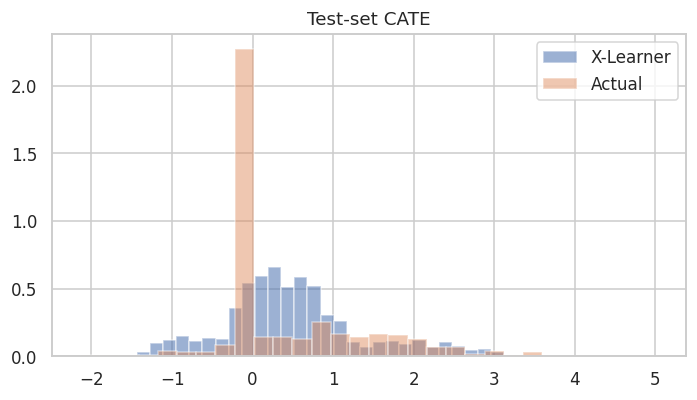

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.hist(cate_test, bins=30, density=True, alpha=0.55, label="X-Learner")
ax.hist(tau[test], bins=30, density=True, alpha=0.45, label="Actual")
ax.set_title("Test-set CATE")
ax.legend()
fig.tight_layout()
plt.show()


### Validating CATE without TMLE

We build a data frame with outcome, treatment, true τ, and model CATE (like the Python `df`). For the TMLE section we will add propensity `p` and inference columns (`col_0` … `col_9`).


### Uplift Curve With Ground Truth

If the true treatment effect is known (as in simulations), the uplift curve of a model uses the cumulative sum of the treatment effect sorted by the model’s CATE estimate. In the figure below, the uplift curve of the X-Learner shows positive lift close to the optimal lift by the ground truth.

- **x-axis**: fraction of samples (0 to 1), ordered by predicted CATE (descending).
- **y-axis**: cumulative sum of true τ in that order, normalized so the final value is 1 (gain curve).


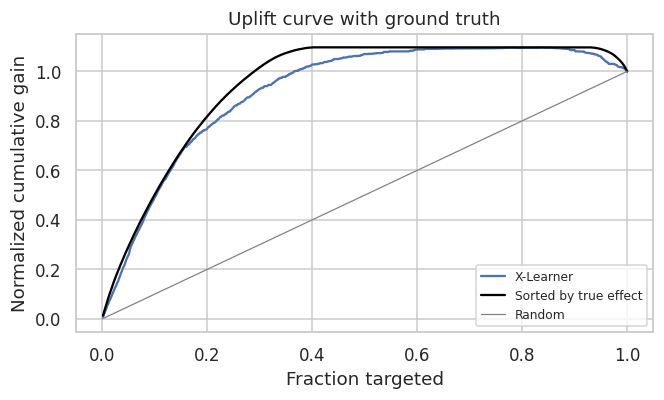

In [5]:
frac, cum, norm = cumgain(cate_test, tau[test])
frac_opt, cum_opt, norm_opt = cumgain(tau[test], tau[test])
fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.plot(frac, norm, label="X-Learner")
ax.plot(frac_opt, norm_opt, color="black", label="Sorted by true effect")
ax.plot([0, 1], [0, 1], color="grey", lw=0.8, label="Random")
ax.set_xlabel("Fraction targeted")
ax.set_ylabel("Normalized cumulative gain")
ax.set_title("Uplift curve with ground truth")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


The X-Learner curve is close to the optimal curve (sorted by true τ). For later use we compute the gain matrix via `get_cumgain` (Python: cumulative gain with ground truth):


### Uplift Curve Without Ground Truth

If the true treatment effect is unknown (as in practice), the uplift curve of a model uses the cumulative mean difference of outcome in the treatment and control group sorted by the model’s CATE estimate. In the figure below, the uplift curves of the X-Learner and the ground truth can show no lift or be misleading when we do not use the true τ.

Without the true effect, the curve uses the cumulative difference in observed outcomes between treated and control units, ordered by the predicted CATE.


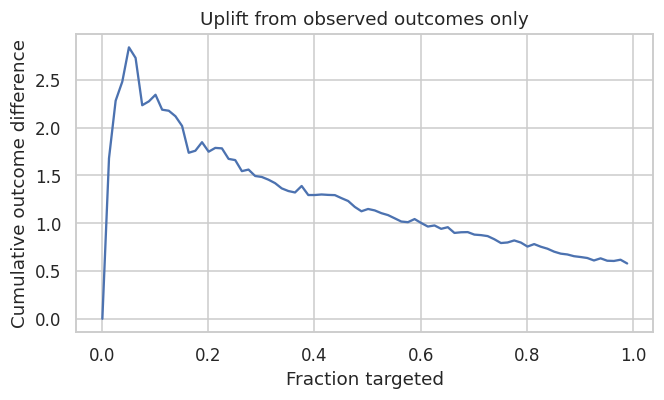

In [6]:
frac_obs, gain_obs = None, None
order = np.argsort(-cate_test)
yy, ww = y[test][order], w[test][order]
n = len(yy)
gain_obs = np.empty(n)
for i in range(n):
    n1 = int((ww[: i + 1] == 1).sum())
    n0 = i + 1 - n1
    gain_obs[i] = 0.0 if n1 == 0 or n0 == 0 else (yy[: i + 1][ww[: i + 1] == 1].mean() - yy[: i + 1][ww[: i + 1] == 0].mean())
frac_obs = np.arange(1, n + 1) / n
fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.plot(frac_obs[::10], gain_obs[::10])
ax.set_title("Uplift from observed outcomes only")
ax.set_xlabel("Fraction targeted")
ax.set_ylabel("Cumulative outcome difference")
fig.tight_layout()
plt.show()


Without ground truth, the “observed” curve can look flat or noisy; using TMLE (or another robust estimator) as a proxy for τ helps validate the ranking, as in the [Python example](https://causalml.readthedocs.io/en/latest/examples/validation_with_tmle.html).

### TMLE (Part A)

**Targeted Maximum Likelihood Estimation (TMLE)** provides a doubly robust, efficient estimate of the average treatment effect. The [Python example](https://causalml.readthedocs.io/en/latest/examples/validation_with_tmle.html) uses `get_tmlegain` and `get_tmleqini` with cross-fitting (e.g. `n_segment=5`, `KFold(n_splits=5)`) to build uplift and Qini curves with TMLE as a proxy for ground truth. In R we approximate this with segment-level TMLE: split the test set into segments by CATE rank, run TMLE within each segment, then build cumulative gain and Qini curves.

### Prepare dataframe with inference columns

We add the covariate columns to the dataframe for TMLE (Python: `inference_cols = ['col_0', ..., 'col_9']`).


### Uplift Curve with TMLE as Ground Truth

By using TMLE as a proxy for the ground truth, the uplift curves become closer to the curves we would get with the true τ. We use 5 segments (Python: `n_segment=5`). The following chunks require the **tmle** package.

#### Uplift curve without CI

Python: `get_tmlegain(..., ci=False)` and `plot_tmlegain(...)` or `plot(..., kind='gain', tmle=True)`.

### ATE with TMLE (R `tmle` package)

If the **tmle** package is installed, we can estimate the ATE on the test set and compare it to the meta-learner ATE (optional; Python doc focuses on gain/qini with TMLE).


In [7]:
tmle_test = tmle_ate(X[test], w[test], y[test], seed=1)
print(pd.Series({k: tmle_test[k] for k in ("ate", "se", "ci_lower", "ci_upper")}).round(3))
print("X-Learner mean CATE on the test set", round(float(cate_test.mean()), 3))


ate         0.505
se          0.106
ci_lower    0.297
ci_upper    0.712
dtype: float64
X-Learner mean CATE on the test set 0.494


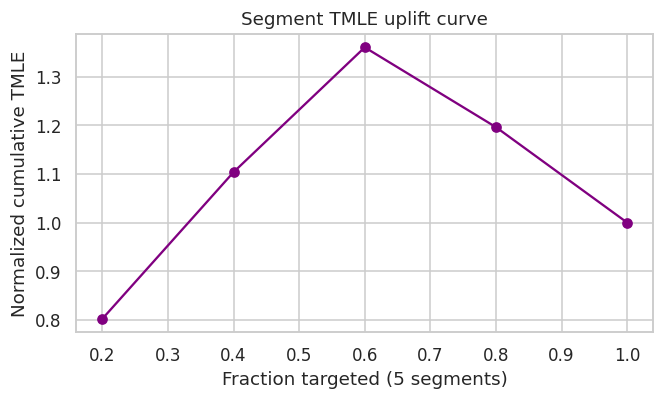

Segment TMLE ATEs [ 1.952  0.735  0.625 -0.4   -0.478]


In [8]:
order = np.argsort(-cate_test)
n_seg = 5
segments = np.array_split(order, n_seg)
seg_ate = []
for seg in segments:
    fit = tmle_ate(X[test][seg], w[test][seg], y[test][seg], seed=2)
    seg_ate.append(fit["ate"])
seg_ate = np.asarray(seg_ate)
cum_seg = np.cumsum(seg_ate)
norm_seg = cum_seg / cum_seg[-1] if abs(cum_seg[-1]) > 1e-8 else cum_seg
frac_seg = np.arange(1, n_seg + 1) / n_seg
fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.plot(frac_seg, norm_seg, marker="o", color="purple")
ax.set_title("Segment TMLE uplift curve")
ax.set_xlabel("Fraction targeted (5 segments)")
ax.set_ylabel("Normalized cumulative TMLE")
fig.tight_layout()
plt.show()
print("Segment TMLE ATEs", np.round(seg_ate, 3))


#### Uplift curve without CI

Python: `get_tmlegain(..., ci=False)` and `plot_tmlegain(...)`. Segment-level TMLE below (5 segments; requires **tmle** package).


#### AUUC Score

Python: `auuc_score(..., tmle=True)`. With ground truth we use the normalized cumulative gain; with TMLE we can use the area under the segment TMLE gain curve. Below: AUUC with true τ (like Python when τ is known).


In [9]:
auuc_truth = float(np.trapezoid(norm, frac))
auuc_tmle = float(np.trapezoid(norm_seg, frac_seg))
print(pd.DataFrame([
    {"curve": "X-Learner vs true tau", "auuc": auuc_truth},
    {"curve": "Segment TMLE", "auuc": auuc_tmle},
]).round(3).to_string(index=False))


                curve  auuc
X-Learner vs true tau 0.920
         Segment TMLE 0.912


#### Uplift curve with CI

Python: `get_tmlegain(..., ci=True)` and `plot_tmlegain(..., ci=True)` use cross-fitting for confidence intervals. The R segment-level TMLE above does not implement CI; you could bootstrap segment ATEs for an approximate interval.

### Qini Curve with TMLE as Ground Truth

Python: `get_tmleqini`, `plot_tmleqini`, and `plot(..., kind='qini', tmle=True)`. We build a Qini-like curve from segment-level TMLE: cumulative incremental outcome when treating top k% (cumsum of segment ATE × segment size).

#### Qini curve without CI


#### Qini Score

Python: `qini_score(..., tmle=True)`. Area under the Qini curve. With ground truth and with TMLE (when **tmle** is available):


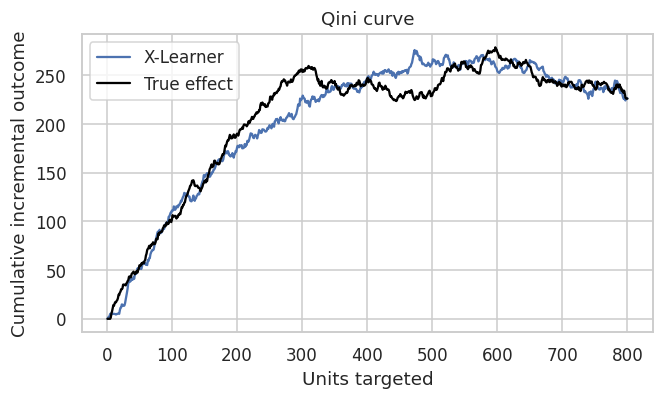

Qini score, model 204.57
Qini score, oracle 206.437
Segment-TMLE Qini path [1.952 2.686 3.311 2.912 2.434]


In [10]:
xs, q_model = qini_curve(y[test], w[test], cate_test)
xs_t, q_true = qini_curve(y[test], w[test], tau[test])
fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.plot(xs, q_model, label="X-Learner")
ax.plot(xs_t, q_true, color="black", label="True effect")
ax.set_title("Qini curve")
ax.set_xlabel("Units targeted")
ax.set_ylabel("Cumulative incremental outcome")
ax.legend()
fig.tight_layout()
plt.show()
print("Qini score, model", round(float(np.trapezoid(q_model, xs) / len(xs)), 3))
print("Qini score, oracle", round(float(np.trapezoid(q_true, xs_t) / len(xs_t)), 3))
qini_tmle = np.cumsum(seg_ate)
print("Segment-TMLE Qini path", np.round(qini_tmle, 3))


#### Qini curve with CI

Python: `get_tmleqini(..., ci=True)` and `plot_tmleqini(..., ci=True)`. The R segment-level TMLE above does not implement CI for the Qini curve.

### Qini curve with ground truth (reference)

For comparison, the standard Qini curve using true τ (Python: `plot(df, kind='qini', ...)` with `treatment_effect_col='tau'`):


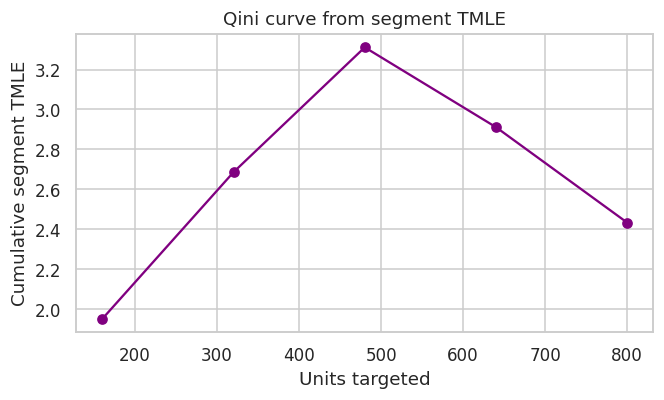

In [11]:
fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.plot(np.arange(1, n_seg + 1) * (len(test) / n_seg), qini_tmle, marker="o", color="purple")
ax.set_title("Qini curve from segment TMLE")
ax.set_xlabel("Units targeted")
ax.set_ylabel("Cumulative segment TMLE")
fig.tight_layout()
plt.show()


## Part B: Use case — LaLonde (NSW job training)

In applications you rarely know individual τ. You still need to check whether an uplift model’s **ranking** is plausible. **TMLE on segments** (or cross-fitted TMLE in production) gives a doubly robust proxy for segment-level effects, similar to Part A but without a true τ column.

The **LaLonde / NSW** sample in `causaldata` combines the NSW experimental treated units with non-experimental comparison groups (observational controls). Effects are not identified as cleanly as in a pure RCT; this notebook uses the data **only** to illustrate the uplift + TMLE validation workflow (X-Learner, observed gain curve, segment TMLE gain/Qini)—not to claim a causal ATE for policy.

### Data

- **Treatment:** `treat` (1 = job training, 0 = control)
- **Outcome:** `re78` (real earnings in 1978)
- **Covariates:** age, education, race, marital status, `nodegree`, `re74`, `re75`

Covariates are expanded to a numeric design matrix for the meta-learner; The same numeric covariates are used for the X-Learner and for TMLE.


In [12]:
from causaldata import nsw_mixtape
nsw = nsw_mixtape.load_pandas().data.copy()
print("NSW / LaLonde columns:", list(nsw.columns))
print(nsw["data_id"].value_counts().to_string())
nsw = nsw[nsw["data_id"] == "Dehejia-Wahba Sample"].copy()
lal_features = ["age", "educ", "black", "hisp", "marr", "nodegree", "re74", "re75"]
X_l = nsw[lal_features].to_numpy(dtype=float)
y_l = nsw["re78"].to_numpy(dtype=float)
w_l = nsw["treat"].to_numpy(dtype=int)
print("n", len(y_l), "treated", int(w_l.sum()))


NSW / LaLonde columns: ['data_id', 'treat', 'age', 'educ', 'black', 'hisp', 'marr', 'nodegree', 're74', 're75', 're78']
data_id
Dehejia-Wahba Sample    445
n 445 treated 185


### Train–test split and X-Learner

Same 50/50 split idea as Part A, with `random_state=42`.


In [13]:
rng = np.random.default_rng(42)
te = rng.choice(len(y_l), size=len(y_l) // 2, replace=False)
tr = np.setdiff1d(np.arange(len(y_l)), te)
learner_lal = XLearner(learner="rf", n_estimators=N_EST, random_state=42)
learner_lal.fit(X_l[tr], w_l[tr], y_l[tr], feature_names=lal_features)
cate_lal = learner_lal.predict(X_l[te])
print("Test mean CATE", round(float(cate_lal.mean()), 1))


Test mean CATE 1468.7


### Uplift from observed outcomes only

There is no true CATE column: the curve uses cumulative treatment–control outcome contrasts along the X-Learner ranking.


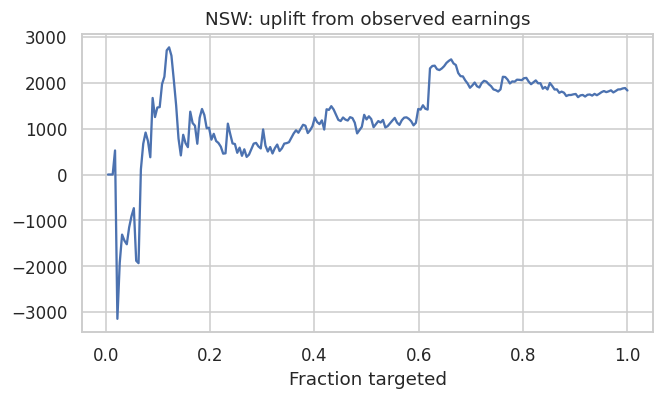

In [14]:
order = np.argsort(-cate_lal)
yy, ww = y_l[te][order], w_l[te][order]
gain = np.empty(len(yy))
for i in range(len(yy)):
    n1 = int((ww[: i + 1] == 1).sum())
    n0 = i + 1 - n1
    gain[i] = 0.0 if n1 == 0 or n0 == 0 else yy[: i + 1][ww[: i + 1] == 1].mean() - yy[: i + 1][ww[: i + 1] == 0].mean()
fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.plot(np.arange(1, len(gain) + 1) / len(gain), gain)
ax.set_title("NSW: uplift from observed earnings")
ax.set_xlabel("Fraction targeted")
fig.tight_layout()
plt.show()


### TMLE on the test set and by segment

Optional **tmle** steps: overall ATE on the test sample, then the same **five-segment** cumulative gain and Qini-style curve as in Part A, overlaid with the **normalized observed** gain for the X-Learner (not comparable to Part A’s “optimal by τ” line).


Test-set TMLE {'ate': 2020.2, 'se': 856.5, 'ci_lower': 341.5, 'ci_upper': 3698.9}


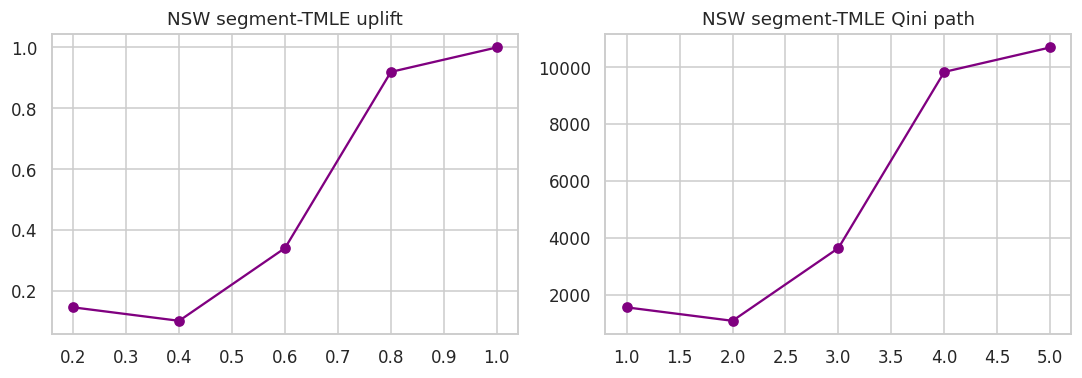

Segment ATEs [1560.8 -472.9 2555.9 6187.9  859.9]


In [15]:
overall = tmle_ate(X_l[te], w_l[te], y_l[te], seed=3)
print("Test-set TMLE", {k: round(overall[k], 1) for k in ("ate", "se", "ci_lower", "ci_upper")})
order = np.argsort(-cate_lal)
n_seg_l = 5
seg_ate_l = []
for seg in np.array_split(order, n_seg_l):
    seg_ate_l.append(tmle_ate(X_l[te][seg], w_l[te][seg], y_l[te][seg], seed=4)["ate"])
seg_ate_l = np.asarray(seg_ate_l)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
frac = np.arange(1, n_seg_l + 1) / n_seg_l
cum = np.cumsum(seg_ate_l)
axes[0].plot(frac, cum / cum[-1] if abs(cum[-1]) > 1 else cum, marker="o", color="purple")
axes[0].set_title("NSW segment-TMLE uplift")
axes[1].plot(np.arange(1, n_seg_l + 1), np.cumsum(seg_ate_l), marker="o", color="purple")
axes[1].set_title("NSW segment-TMLE Qini path")
fig.tight_layout()
plt.show()
print("Segment ATEs", np.round(seg_ate_l, 1))


**Interpretation:** On observational data, segment TMLE is noisy with small *n* per segment; prefer more segments, cross-fitting, or a larger sample for stable curves. The point is methodological alignment with Part A when **τ** is unknown.

## Summary and Conclusions

**TMLE is the "gold standard" for robust causal estimation when using Machine Learning.**

In the context of **Causal ML and Uplift**, TMLE is the engine that ensures your fancy ML models don't lie to you about the treatment effect. While Meta-learners (T/X-Learners) provide the *architecture* for estimating heterogeneous effects, TMLE provides the *statistical guarantees* that allow you to trust the results and make decisions (like sending a coupon or prescribing a drug) with known risk levels.

**Part A** used synthetic data with known τ to show when observed-only uplift curves mislead and how segment TMLE tracks validation against τ. **Part B** applied the same workflow to LaLonde: without τ, only observed gain plus TMLE-by-segment is available—interpret cautiously on small samples and observational designs.

| Element | Python CausalML | This notebook |
|--------|------------------|------------------|
| Part A data | `synthetic_data(mode=1, n=1e6, p=10, sigma=5)` | `synthetic_data(mode=1, n=20000, p=10, sigma=5)` |
| Part B data | — | `causaldata.nsw_mixtape` (Dehejia–Wahba sample) |
| Split | `train_test_split(..., test_size=0.5, random_state=42)` | 50/50 train-test, `set.seed(42)` |
| CATE | `BaseXRegressor(learner=LGBMRegressor())` | `XLearner(learner="rf")` |
| Uplift with τ | `plot(df, ...)`, `get_cumgain` | `plot_gain(..., treatment_effect_col='tau')`, `get_cumgain` (Part A) |
| Uplift without τ | `plot(df.drop('tau', axis=1), ...)` | `plot_gain(...)` without `treatment_effect_col` (Part A: `df_no_tau`; Part B: `df_lal`) |
| TMLE / inference | `inference_cols`, `get_tmlegain`, `plot_tmlegain`, `plot(..., kind='gain', tmle=True)` | Segment-level `tmle::tmle()`; Part A also adds `col_0`…`col_9` for illustration |
| AUUC | `auuc_score()`, `auuc_score(..., tmle=True)` | `colMeans(get_cumgain(..., normalize=TRUE))` with τ (Part A); segment TMLE curve where shown |
| Qini | `get_tmleqini`, `plot_tmleqini`, `plot(..., kind='qini', tmle=True)`, `qini_score(..., tmle=True)` | `plot_qini()` with τ (Part A); segment TMLE Qini-style curve (Parts A–B) |

## References

- **References**: [Uplift Curves with TMLE Example](https://causalml.readthedocs.io/en/latest/examples/validation_with_tmle.html); [causalml.metrics.visualize](https://github.com/uber/causalml/blob/master/causalml/metrics/visualize.py) (`plot`, `get_cumgain`, `get_cumlift`, `get_qini`, `get_tmlegain`, `get_tmleqini`, `auuc_score`, `qini_score`).
